In [44]:
def clean_endpoint_from_fit(seg_xy, seg_a, fit):
    inliers = fit["inliers"]

    # match each inlier back to original seg_xy index
    good_idx = []
    for p in inliers:
        idx = np.argmin(np.linalg.norm(seg_xy - p, axis=1))
        good_idx.append(idx)

    good_idx = np.array(sorted(set(good_idx)))

    # last clean inlier in angular order
    last = good_idx[-1]
    return seg_xy[last], seg_a[last]

def extract_combined_arc(ranges, angles, angle_min_deg=225.0, angle_max_deg=30.0,max_range=3):
    angles_deg = np.degrees(angles) % 360.0
    mask = (angles_deg >= angle_min_deg) | (angles_deg <= angle_max_deg)
    valid = mask & np.isfinite(ranges) & (ranges > 0.15) & (ranges < max_range)

    arc_ranges = ranges[valid]
    arc_angles = angles_deg[valid]

    # shift angles so 225°→359° comes first, then 0°→30°
    # remap: angles >= 225 stay as-is, angles < 225 get +360
    shifted = np.where(arc_angles < angle_min_deg, arc_angles + 360.0, arc_angles)
    order = np.argsort(shifted)

    arc_ranges = arc_ranges[order]
    arc_angles = arc_angles[order]  # keep original degrees for readability

    x = arc_ranges * np.cos(np.radians(arc_angles))
    y = arc_ranges * np.sin(np.radians(arc_angles))
    arc_xy = np.column_stack([x, y])

    return arc_ranges, arc_angles, arc_xy

# def extract_combined_arc(ranges, angles, 
#                           angle_min_deg=225.0, angle_max_deg=30.0,
#                           max_range=3.0):
#     angles_deg = np.degrees(angles) % 360.0
#     mask = (angles_deg >= angle_min_deg) | (angles_deg <= angle_max_deg)

#     # segmentation input — near valid points only
#     valid = mask & np.isfinite(ranges) & (ranges > 0.15) & (ranges < max_range)

#     arc_ranges = ranges[valid]
#     arc_angles = angles_deg[valid]

#     shifted = np.where(arc_angles < angle_min_deg, arc_angles + 360.0, arc_angles)
#     order = np.argsort(shifted)

#     arc_ranges = arc_ranges[order]
#     arc_angles = arc_angles[order]

#     x = arc_ranges * np.cos(np.radians(arc_angles))
#     y = arc_ranges * np.sin(np.radians(arc_angles))
#     arc_xy = np.column_stack([x, y])

#     # raw arc mask — for terminal dropout inspection
#     # includes far points but excludes inf/nan
#     raw_valid = mask & np.isfinite(ranges) & (ranges > 0.15)
    
#     return arc_ranges, arc_angles, arc_xy, raw_valid

# ── Step 2: mad_filter() ─────────────────────────────────────────────────
def mad_filter(arc_ranges, arc_angles, arc_xy, threshold=2.5):
    """
    Median Absolute Deviation filter on arc ranges.
    Removes beams whose range deviates more than threshold * MAD from median.
    Returns filtered (arc_ranges, arc_angles, arc_xy).
    """
    median = np.median(arc_ranges)
    mad    = np.median(np.abs(arc_ranges - median))
    if mad < 1e-6:
        return arc_ranges, arc_angles, arc_xy   # flat surface, nothing to filter

    mask = np.abs(arc_ranges - median) <= threshold * mad
    return arc_ranges[mask], arc_angles[mask], arc_xy[mask]



def segment_points(arc_ranges, arc_angles, arc_xy,
                   threshold=0.15, min_points=5):
    if len(arc_ranges) < 2:
        return []

    segments = []
    seg_start = 0

    for i in range(1, len(arc_ranges)):
        angle_gap_rad = abs(np.radians(arc_angles[i] - arc_angles[i-1]))
        if angle_gap_rad > np.pi:
            angle_gap_rad = 2*np.pi - angle_gap_rad

        # expected Cartesian spacing on flat surface
        tolerance = arc_ranges[i-1] * abs(np.sin(angle_gap_rad / 2)) * 2

        # Cartesian distance between adjacent points
        cartesian = np.linalg.norm(arc_xy[i] - arc_xy[i-1])

        # direct range difference — catches depth jumps missed by Cartesian
        range_jump = abs(arc_ranges[i] - arc_ranges[i-1])

        print(f"  i={i:3d}  a={arc_angles[i-1]:.1f}→{arc_angles[i]:.1f}  r={arc_ranges[i]:.3f}  cart={cartesian:.4f}  tol={tolerance:.4f}  rjump={range_jump:.4f}  split={'YES' if abs(cartesian-tolerance)>threshold else 'no'}")
        # split on either signal
        if abs(cartesian - tolerance) > threshold :#or range_jump > threshold:
            if (i - seg_start) >= min_points:
                segments.append((
                    arc_ranges[seg_start:i],
                    arc_angles[seg_start:i],
                    arc_xy[seg_start:i]
                ))
            seg_start = i

    if (len(arc_ranges) - seg_start) >= min_points:
        segments.append((
            arc_ranges[seg_start:],
            arc_angles[seg_start:],
            arc_xy[seg_start:]
        ))

    return segments

def find_orientation_change(seg_xy, window=5, min_angle_deg=20.0, max_angle_deg=130.0):
    """
    Walk along a segment's Cartesian points looking for a significant
    direction change. Uses a local window to compute stable bearing vectors
    before and after each candidate point.

    Returns list of dicts:
        {
          'index'       : int,        # index into seg_xy
          'point'       : np.array,   # (x, y) of junction
          'source_deg'  : float,      # incoming bearing (degrees)
          'target_deg'  : float,      # outgoing bearing (degrees)
          'radian_diff' : float,      # signed angle change (radians)
          'type'        : str,        # 'INTERNAL' or 'EXTERNAL'
        }
    """
    results = []
    n = len(seg_xy)
    if n < window * 2 + 1:
        return results

    for i in range(window, n - window):
        # stable incoming vector — average over window points before i
        vec_in  = seg_xy[i] - seg_xy[i - window]
        # stable outgoing vector — average over window points after i
        vec_out = seg_xy[i + window] - seg_xy[i]

        source = np.arctan2(vec_in[1],  vec_in[0])
        target = np.arctan2(vec_out[1], vec_out[0])

        # normalise both to [0, 2π)
        source = source % (2 * np.pi)
        target = target % (2 * np.pi)

        radian_diff = source - target

        # normalise diff to (-π, π]
        radian_diff = (radian_diff + np.pi) % (2 * np.pi) - np.pi

        if min_angle_deg <= abs(np.degrees(radian_diff)) <= max_angle_deg:    

            corner_type = 'EXTERNAL' if radian_diff > 0 else 'INTERNAL'
            results.append({
                'index'       : i,
                'point'       : seg_xy[i],
                'source_deg'  : np.degrees(source),
                'target_deg'  : np.degrees(target),
                'radian_diff' : radian_diff,
                'type'        : corner_type,
            })
    return results


import numpy as np


def point_line_distance(points, p0, p1):
    """
    Perpendicular distance from points to infinite line p0->p1.
    points: (N, 2)
    """
    v = p1 - p0
    denom = np.linalg.norm(v)

    if denom < 1e-9:
        return np.linalg.norm(points - p0, axis=1)

    return np.abs(np.cross(v, points - p0)) / denom


def pca_direction_angle(xy):
    """
    PCA/TLS direction angle of a 2D point cloud.
    Returns angle in radians.
    """
    if len(xy) < 2:
        return 0.0

    c = xy.mean(axis=0)
    X = xy - c

    _, _, vh = np.linalg.svd(X, full_matrices=False)
    v = vh[0]

    return np.arctan2(v[1], v[0])


def abs_line_angle_diff_deg(a, b):
    """
    Absolute difference between two line directions.
    Line has 180° ambiguity, so 0° and 180° are same.
    """
    d = (a - b + np.pi) % (2 * np.pi) - np.pi
    d = abs(np.degrees(d))
    return min(d, 180.0 - d)


def split_one_segment_by_line_deviation(
    seg_r,
    seg_a,
    seg_xy,
    deviation_threshold=0.05,
    min_points=8,
    min_angle_change_deg=12.0,
    debug=False,
):
    """
    Splits one segment when it can no longer be represented by one straight line.

    Important:
    - Rejects fake splits if both sides are still nearly collinear.
    - Good for connected L-corners.
    - Avoids splitting noisy straight walls into two pieces.
    """

    n = len(seg_xy)

    if n < 2 * min_points:
        return [(seg_r, seg_a, seg_xy)]

    out = []
    start = 0
    i = start + min_points

    while i < n:
        pts = seg_xy[start:i + 1]

        p0 = pts[0]
        p1 = pts[-1]

        dists = point_line_distance(pts, p0, p1)
        max_dev_idx_local = int(np.argmax(dists))
        max_dev = float(dists[max_dev_idx_local])

        if max_dev > deviation_threshold:
            split_idx = start + max_dev_idx_local

            left_xy = seg_xy[start:split_idx]
            right_xy = seg_xy[split_idx:i + 1]

            left_n = len(left_xy)
            right_n = len(right_xy)

            if left_n >= min_points and right_n >= min_points:
                left_angle = pca_direction_angle(left_xy)
                right_angle = pca_direction_angle(right_xy)
                angle_change = abs_line_angle_diff_deg(left_angle, right_angle)

                if debug:
                    print(
                        f"SPLIT CANDIDATE: "
                        f"start={start}, i={i}, split_idx={split_idx}, "
                        f"angle={seg_a[split_idx]:.1f}, "
                        f"max_dev={max_dev:.4f}, "
                        f"angle_change={angle_change:.1f}, "
                        f"left_n={left_n}, right_n={right_n}"
                    )

                # Reject fake split on same straight wall
                if angle_change < min_angle_change_deg:
                    if debug:
                        print("  rejected: collinear pieces")
                    i += 1
                    continue

                # Accept split
                if debug:
                    print("  accepted")

                out.append((
                    seg_r[start:split_idx],
                    seg_a[start:split_idx],
                    seg_xy[start:split_idx],
                ))

                start = split_idx
                i = start + min_points
                continue

        i += 1

    # Add final remaining piece
    if (n - start) >= min_points:
        out.append((
            seg_r[start:n],
            seg_a[start:n],
            seg_xy[start:n],
        ))

    return out


def split_segments_by_line_deviation(
    segments,
    deviation_threshold=0.05,
    min_points=5,
    min_angle_change_deg=12.0,
    debug=False,
):
    """
    Input/output format same as segment_points():
        [(seg_ranges, seg_angles, seg_xy), ...]

    Usage:
        segments = segment_points(arc_r, arc_a, arc_xy)
        segments = split_segments_by_line_deviation(segments)
    """

    refined = []

    for si, (seg_r, seg_a, seg_xy) in enumerate(segments):
        if debug:
            print(f"\nChecking segment {si}: n={len(seg_xy)} "
                  f"angle={seg_a[0]:.1f}->{seg_a[-1]:.1f}")

        pieces = split_one_segment_by_line_deviation(
            seg_r,
            seg_a,
            seg_xy,
            deviation_threshold=deviation_threshold,
            min_points=min_points,
            min_angle_change_deg=min_angle_change_deg,
            debug=debug,
        )

        refined.extend(pieces)

    return refined


def debug_segment_geometry(segments, title="Segments"):
    print(f"\n{title}")
    for si, (sr, sa, sxy) in enumerate(segments):
        p0, p1 = sxy[0], sxy[-1]
        chord = np.linalg.norm(p1 - p0)

        if len(sxy) >= 3:
            dists = point_line_distance(sxy, p0, p1)
            max_i = int(np.argmax(dists))
            max_dev = float(dists[max_i])
        else:
            max_i = -1
            max_dev = 0.0

        print(
            f"Seg {si}: n={len(sxy):3d} "
            f"angle={sa[0]:6.1f}->{sa[-1]:6.1f} "
            f"range={sr.min():.3f}-{sr.max():.3f} "
            f"chord={chord:.3f} "
            f"max_dev={max_dev:.4f} at local_idx={max_i}"
        )
# ── Test + Plot ───────────────────────────────────────────────────────────

def ransac_line(points, n_iter=100, threshold=0.05, min_inliers=8):
    """
    RANSAC line fit on 2D point cloud.
    
    Returns:
        best_mask  : boolean array, True = inlier
        best_n     : normal vector (unit, pointing toward origin)
        best_d     : perpendicular distance from origin to line
        best_count : number of inliers
    Or None if no valid line found.
    """
    n_pts = len(points)
    if n_pts < 2:
        return None

    best_mask  = None
    best_count = 0
    best_n     = None
    best_d     = 0.0

    for _ in range(n_iter):
        # 1. Sample 2 random points
        idx = random.sample(range(n_pts), 2)
        p1, p2 = points[idx[0]], points[idx[1]]

        # 2. Compute line normal
        direction = p2 - p1
        seg_len   = np.linalg.norm(direction)
        if seg_len < 1e-6:
            continue

        n = np.array([-direction[1], direction[0]]) / seg_len
        d = float(np.dot(n, p1))

        # Keep d positive (temp convention for scoring only)
        if d < 0:
            n = -n
            d = -d

        # 3. Count inliers
        dists = np.abs(points @ n - d)
        mask  = dists < threshold
        count = int(mask.sum())

        if count > best_count:
            best_count = count
            best_mask  = mask.copy()
            best_n     = n.copy()
            best_d     = d

    if best_mask is None or best_count < min_inliers:
        return None

    return best_mask, best_n, best_d, best_count

def pca_fit(arc_points):
        """
        Fit a line to arc_points using PCA.
        Returns (normal, distance, centroid, eigenvalues) or None if too few points.
        """
        if len(arc_points) < 5:
            return None

        cx, cy = arc_points.mean(axis=0)
        centroid = np.array([cx, cy])

        # Center the points
        centered = arc_points - centroid

        # Covariance matrix
        cov = (centered.T @ centered) / len(arc_points)

        # Eigendecomposition — eigh returns sorted ascending
        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        # smallest eigenvector = normal direction (perpendicular to wall)
        normal = eigenvectors[:, 0]

        # Flip normal to point toward robot at origin
        # If normal points same way as centroid-from-origin, flip it
        if np.dot(normal, centroid) > 0:
            normal = -normal

        # Distance from origin to line
        distance = float(abs(np.dot(normal, centroid)))

        ratio = eigenvalues[1] / (eigenvalues[0] + 1e-9)

        return normal, distance, centroid, eigenvalues, ratio

def fit_segment(sxy, n_iter=100, threshold=0.05, min_inliers=8):
    """
    RANSAC + PCA fit on a segment's Cartesian points.
    Returns dict or None if fit fails.
    """
    if len(sxy) < min_inliers:
        return None

    ransac_result = ransac_line(sxy, n_iter=n_iter,
                                threshold=threshold,
                                min_inliers=min_inliers)
    if ransac_result is None:
        return None

    mask, _, _, _ = ransac_result
    inliers = sxy[mask]

    pca_result = pca_fit(inliers)



    if pca_result is None:
        return None

    normal, distance, centroid, eigenvalues, ratio = pca_result

    print(f"  fit_segment: distance={distance:.3f}m  ratio={ratio:.1f}  centroid=({centroid[0]:.3f},{centroid[1]:.3f})")

    if distance > 3.0:
        print(f"  fit_segment: REJECTED — distance {distance:.3f}m > 3.0m")
        return None

    print(f"  fit_segment: ACCEPTED")
    
    if ratio < 5.0:   # not a clean wall — reject
        return None

    return {
        'normal'    : normal,      # unit normal pointing toward origin
        'distance'  : distance,    # perpendicular distance from origin
        'centroid'  : centroid,    # mean of inlier points
        'eigenvalues': eigenvalues,
        'ratio'     : ratio,
        'inliers'   : inliers,
        'n_inliers' : int(mask.sum()),
        'n_total'   : len(sxy),
    }


# fits = []
# for i, (_, _, sxy) in enumerate(segments):
#     f = fit_segment(sxy)
#     if f is not None:
#         print(f"Seg {i}: ratio={f['ratio']:.1f}  "
#               f"d={f['distance']:.3f}m  "
#               f"normal=[{f['normal'][0]:.3f}, {f['normal'][1]:.3f}]  "
#               f"inliers={f['n_inliers']}/{f['n_total']}")
#     else:
#         print(f"Seg {i}: rejected")
#     fits.append(f)

# def smart_fit_segments(segments, inlier_ratio_threshold=0.80,
#                        window=25, min_angle_deg=25.0, max_angle_deg=130.0,
#                        min_points=15):
#     """
#     For each segment:
#       1. Quick RANSAC+PCA fit
#       2. If inlier_ratio < threshold → try kink split → refit each half
#       3. Returns list of (fit, sxy) tuples — only valid fits kept
#     """
#     valid_fits = []   # list of (fit_result, sxy)

#     for seg_idx, (_, _, sxy) in enumerate(segments):

#         if len(sxy) < min_points:
#             print(f"Seg {seg_idx}: skipped — too few points ({len(sxy)})")
#             continue

#         f = fit_segment(sxy)

#         if f is None:
#             print(f"Seg {seg_idx}: fit failed")
#             continue

#         inlier_ratio = f['n_inliers'] / f['n_total']

#         if inlier_ratio >= inlier_ratio_threshold:
#             # clean segment — keep as-is
#             print(f"Seg {seg_idx}: clean  "
#                   f"ratio={f['ratio']:.1f}  "
#                   f"inliers={f['n_inliers']}/{f['n_total']} ({inlier_ratio:.0%})  "
#                   f"d={f['distance']:.3f}m")
#             valid_fits.append((f, sxy))

#         else:
#             # poor fit — attempt kink split
#             print(f"Seg {seg_idx}: poor inlier ratio ({inlier_ratio:.0%}) "
#                   f"— attempting kink split")

#             kinks = find_orientation_change(sxy, window=window,
#                                             min_angle_deg=min_angle_deg,
#                                             max_angle_deg=max_angle_deg)

#             if not kinks:
#                 print(f"  → no kink found — discarding segment")
#                 continue

#             # use strongest kink (largest |radian_diff|)
#             best_kink = max(kinks, key=lambda k: abs(k['radian_diff']))
#             k_idx = best_kink['index']

#             print(f"  → kink at idx={k_idx}  "
#                   f"type={best_kink['type']}  "
#                   f"angle={np.degrees(best_kink['radian_diff']):.1f}°  "
#                   f"pt=({best_kink['point'][0]:.3f}, {best_kink['point'][1]:.3f})")

#             half_a = sxy[:k_idx]
#             half_b = sxy[k_idx:]

#             for label, half in [('A', half_a), ('B', half_b)]:
#                 if len(half) < min_points:
#                     print(f"  → half {label}: too few points ({len(half)}) — skipped")
#                     continue

#                 hf = fit_segment(half)
#                 if hf is None:
#                     print(f"  → half {label}: fit failed")
#                     continue

#                 print(f"  → half {label}: ratio={hf['ratio']:.1f}  "
#                       f"inliers={hf['n_inliers']}/{hf['n_total']}  "
#                       f"d={hf['distance']:.3f}m  "
#                       f"normal=[{hf['normal'][0]:.3f}, {hf['normal'][1]:.3f}]")
#                 valid_fits.append((hf, half))

#     return valid_fits

def smart_fit_segments(segments, inlier_ratio_threshold=0.80,
                       window=25, min_angle_deg=25.0, max_angle_deg=130.0,
                       min_points=15):
    """
    For each segment:
      1. Quick RANSAC+PCA fit
      2. If inlier_ratio < threshold → try kink split → refit each half
      3. Stores clean fitted endpoint for terminal edge detection
      4. Returns list of (fit, sxy) tuples
    """
    valid_fits = []

    for seg_idx, (_, seg_a, sxy) in enumerate(segments):

        if len(sxy) < min_points:
            print(f"Seg {seg_idx}: skipped — too few points ({len(sxy)})")
            continue

        f = fit_segment(sxy, min_inliers=min_points)

        if f is None:
            print(f"Seg {seg_idx}: fit failed")
            continue

        inlier_ratio = f['n_inliers'] / f['n_total']

        if inlier_ratio >= inlier_ratio_threshold:
            edge_pt, edge_angle = clean_endpoint_from_fit(sxy, seg_a, f)

            f["edge_point"] = edge_pt
            f["edge_angle"] = edge_angle
            f["seg_idx"] = seg_idx

            print(f"Seg {seg_idx}: clean  "
                  f"ratio={f['ratio']:.1f}  "
                  f"inliers={f['n_inliers']}/{f['n_total']} ({inlier_ratio:.0%})  "
                  f"d={f['distance']:.3f}m  "
                  f"edge=({edge_pt[0]:.3f},{edge_pt[1]:.3f}) @ {edge_angle:.1f}°")

            valid_fits.append((f, sxy))

        else:
            print(f"Seg {seg_idx}: poor inlier ratio ({inlier_ratio:.0%}) "
                  f"— attempting kink split")

            kinks = find_orientation_change(
                sxy,
                window=window,
                min_angle_deg=min_angle_deg,
                max_angle_deg=max_angle_deg
            )

            if not kinks:
                print("  → no kink found — discarding segment")
                continue

            best_kink = max(kinks, key=lambda k: abs(k['radian_diff']))
            k_idx = best_kink['index']

            print(f"  → kink at idx={k_idx}  "
                  f"type={best_kink['type']}  "
                  f"angle={np.degrees(best_kink['radian_diff']):.1f}°  "
                  f"pt=({best_kink['point'][0]:.3f}, {best_kink['point'][1]:.3f})")

            halves = [
                ("A", sxy[:k_idx], seg_a[:k_idx]),
                ("B", sxy[k_idx:], seg_a[k_idx:])
            ]

            for label, half_xy, half_a in halves:
                if len(half_xy) < min_points:
                    print(f"  → half {label}: too few points ({len(half_xy)}) — skipped")
                    continue

                hf = fit_segment(half_xy, min_inliers=min_points)

                if hf is None:
                    print(f"  → half {label}: fit failed")
                    continue

                edge_pt, edge_angle = clean_endpoint_from_fit(half_xy, half_a, hf)

                hf["edge_point"] = edge_pt
                hf["edge_angle"] = edge_angle
                hf["seg_idx"] = seg_idx

                print(f"  → half {label}: ratio={hf['ratio']:.1f}  "
                      f"inliers={hf['n_inliers']}/{hf['n_total']}  "
                      f"d={hf['distance']:.3f}m  "
                      f"normal=[{hf['normal'][0]:.3f}, {hf['normal'][1]:.3f}]  "
                      f"edge=({edge_pt[0]:.3f},{edge_pt[1]:.3f}) @ {edge_angle:.1f}°")

                valid_fits.append((hf, half_xy))

    return valid_fits

def merge_collinear(valid_fits, angle_tol_deg=8.0, dist_tol=0.04,
                    gap_tol=0.15):
    """
    Merge adjacent valid_fits whose fitted walls are collinear.
    Collinear criteria (all must pass):
      - angle between normals < angle_tol_deg
      - distance difference < dist_tol (m)
      - gap between segment endpoints < gap_tol (m)

    After merging, refit the combined point cloud with RANSAC+PCA.
    Returns list of (fit, sxy) — same format as smart_fit_segments().
    """
    if not valid_fits:
        return []

    # work on a copy so we can mutate
    groups = [[valid_fits[0]]]

    for i in range(1, len(valid_fits)):
        fit_prev, sxy_prev = groups[-1][-1]
        fit_curr, sxy_curr = valid_fits[i]

        # ── angle check ───────────────────────────────────────────────────
        dot         = abs(np.dot(fit_prev['normal'], fit_curr['normal']))
        dot         = min(dot, 1.0)   # clamp for arccos
        angle_diff  = np.degrees(np.arccos(dot))

        # ── distance check ────────────────────────────────────────────────
        dist_diff   = abs(fit_prev['distance'] - fit_curr['distance'])

        # ── endpoint gap check ────────────────────────────────────────────
        gap         = np.linalg.norm(sxy_prev[-1] - sxy_curr[0])

        angle_ok    = angle_diff  < angle_tol_deg
        dist_ok     = dist_diff   < dist_tol
        gap_ok      = gap         < gap_tol

        if angle_ok and dist_ok and gap_ok:
            print(f"  merging fit {i-1}→{i}  "
                  f"angle_diff={angle_diff:.1f}°  "
                  f"dist_diff={dist_diff*100:.1f}cm  "
                  f"gap={gap*100:.1f}cm")
            groups[-1].append(valid_fits[i])
        else:
            reason = []
            if not angle_ok: reason.append(f"angle={angle_diff:.1f}°")
            if not dist_ok:  reason.append(f"dist={dist_diff*100:.1f}cm")
            if not gap_ok:   reason.append(f"gap={gap*100:.1f}cm")
            print(f"  keeping fit {i} separate — {', '.join(reason)}")
            groups.append([valid_fits[i]])

    # ── refit each group ──────────────────────────────────────────────────
    merged_fits = []
    for g_idx, group in enumerate(groups):
        if len(group) == 1:
            # no merge needed
            merged_fits.append(group[0])
            f, sxy = group[0]
            print(f"Wall {g_idx}: single segment  "
                  f"pts={len(sxy)}  d={f['distance']:.3f}m  "
                  f"normal=[{f['normal'][0]:.3f}, {f['normal'][1]:.3f}]")
        else:
            # merge point clouds and refit
            combined_sxy = np.vstack([sxy for _, sxy in group])
            hf = fit_segment(combined_sxy)
            if hf is None:
                print(f"Wall {g_idx}: merged refit failed — discarding")
                continue
            merged_fits.append((hf, combined_sxy))
            print(f"Wall {g_idx}: merged {len(group)} segments  "
                  f"pts={len(combined_sxy)}  "
                  f"d={hf['distance']:.3f}m  "
                  f"normal=[{hf['normal'][0]:.3f}, {hf['normal'][1]:.3f}]  "
                  f"ratio={hf['ratio']:.1f}")

    return merged_fits

def oriented_wall_dir(fit, sxy):
    # direction perpendicular to normal
    d = np.array([-fit['normal'][1], fit['normal'][0]], dtype=float)
    d /= np.linalg.norm(d) + 1e-9

    # force direction to follow scan/segment order
    scan_dir = sxy[-1] - sxy[0]
    if np.dot(d, scan_dir) < 0:
        d = -d

    return d


def line_intersection(fit_a, fit_b):
    # line equation: n.x = signed_d
    da = float(np.dot(fit_a['normal'], fit_a['centroid']))
    db = float(np.dot(fit_b['normal'], fit_b['centroid']))

    A = np.array([fit_a['normal'], fit_b['normal']])
    b = np.array([da, db])

    if abs(np.linalg.det(A)) < 1e-6:
        return None

    return np.linalg.solve(A, b)


def classify_segment_pair(fit_a, sxy_a, fit_b, sxy_b,
                          min_corner_deg=20.0,
                          max_corner_deg=160.0):
    if fit_a is None or fit_b is None:
        return None

    dir_a = oriented_wall_dir(fit_a, sxy_a)
    dir_b = oriented_wall_dir(fit_b, sxy_b)

    cross = float(dir_a[0] * dir_b[1] - dir_a[1] * dir_b[0])
    dot   = float(np.dot(dir_a, dir_b))

    radian_diff = np.arctan2(cross, dot)
    angle_deg = abs(np.degrees(radian_diff))

    if not (min_corner_deg <= angle_deg <= max_corner_deg):
        return None

    vertex = line_intersection(fit_a, fit_b)
    if vertex is None:
        return None

    corner_type = 'INTERNAL' if radian_diff > 0 else 'EXTERNAL'

    return {
        'type': corner_type,
        'radian_diff': radian_diff,
        'angle_deg': angle_deg,
        'vertex': vertex,
        'cross': cross,
        'dot': dot,
        'dir_a': dir_a,
        'dir_b': dir_b,
    }


def detect_best_corner(fits):
    best_result = None
    best_score = -1

    for i in range(len(fits) - 1):
        fit_a, sxy_a = fits[i]
        fit_b, sxy_b = fits[i + 1]

        # skip nearly same wall
        normal_dot = abs(float(np.dot(fit_a['normal'], fit_b['normal'])))
        if normal_dot > 0.90:
            print(f"Pair {i}->{i+1}: skipped same wall dot={normal_dot:.2f}")
            continue

        r = classify_segment_pair(fit_a, sxy_a, fit_b, sxy_b)
        if r is None:
            print(f"Pair {i}->{i+1}: invalid")
            continue

        # score: prefer strong fits and nearer visible corner
        score = fit_a['n_inliers'] + fit_b['n_inliers']

        r['seg_a'] = i
        r['seg_b'] = i + 1
        r['score'] = score

        print(
            f"Pair {i}->{i+1}: {r['type']} "
            f"{r['angle_deg']:.1f}° "
            f"vertex=({r['vertex'][0]:.3f}, {r['vertex'][1]:.3f}) "
            f"score={score}"
        )

        if score > best_score:
            best_score = score
            best_result = r

    return best_result

def shift_angle_deg(a_deg, arc_start_deg):
    """
    Convert wrapped angle into continuous angle starting at arc_start_deg.
    Example for arc_start=180:
      180..359 stay same, 0..30 become 360..390
    """
    a = a_deg % 360.0
    return a + 360.0 if a < arc_start_deg else a


def in_wrapped_arc(a_deg, arc_start_deg, arc_end_deg):
    """
    True if angle lies in wrapped arc arc_start -> arc_end.
    Example: 180 -> 30 means [180..360] U [0..30]
    """
    a = a_deg % 360.0
    if arc_start_deg <= arc_end_deg:
        return arc_start_deg <= a <= arc_end_deg
    else:
        return a >= arc_start_deg or a <= arc_end_deg




def detect_terminal_edges_from_fits(
    fits,
    ranges_raw,
    angles_full_rad,
    max_range_interest=2.0,
    lookahead_beams=12,
    min_far_ratio=0.50,
    debug=True,
    arc_end_deg=355.0,      
    arc_end_margin_deg=15.0,  
):
    angles_deg = np.degrees(angles_full_rad) % 360.0
    terminal_edges = []

    for fit_idx, (fit, sxy) in enumerate(fits):
        edge_angle = fit["edge_angle"]
        edge_pt = fit["edge_point"]

        if abs(((edge_angle - arc_end_deg + 180) % 360) - 180) < arc_end_margin_deg:
            if debug:
                print(f"  Terminal check fit {fit_idx}: skipped — edge near arc boundary ({edge_angle:.1f}°)")
            continue

        idx = np.argmin(np.abs(((angles_deg - edge_angle + 180) % 360) - 180))

        ahead_idx = (idx + np.arange(1, lookahead_beams + 1)) % len(ranges_raw)
        ahead_ranges = ranges_raw[ahead_idx]

        far = (~np.isfinite(ahead_ranges)) | (ahead_ranges > max_range_interest)
        far_ratio = np.count_nonzero(far) / len(ahead_ranges)

        if debug:
            print(
                f"Terminal check fit {fit_idx}: "
                f"edge_angle={edge_angle:.1f}, "
                f"edge_pt=({edge_pt[0]:.3f},{edge_pt[1]:.3f}), "
                f"far_ratio={far_ratio:.2f}, "
                f"ahead_ranges={np.round(ahead_ranges, 2)}"
            )

        if far_ratio >= min_far_ratio:
            terminal_edges.append({
                "type": "EXTERNAL_EDGE",
                "fit_idx": fit_idx,
                "seg_idx": fit.get("seg_idx", None),
                "angle": edge_angle,
                "point": edge_pt,
                "far_ratio": far_ratio,
            })

    return terminal_edges

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import random
import os

# ── Load ──────────────────────────────────────────────────────────────────
expt_name= "scan_0000"
DATA_DIR    = os.path.expanduser('./lidar_scans/run_pb_2')

# expt_name= "fake_stub_pillar"
# DATA_DIR    = os.path.expanduser('./fake_data/')
data_path = os.path.join(DATA_DIR, f"{expt_name}.npy")  

data = np.load(data_path, allow_pickle=True).item()

out_dir = os.path.join(DATA_DIR,"P2_corners")
os.makedirs(out_dir, exist_ok=True)

ranges      = np.array(data['ranges'], dtype=np.float32)
angle_min   = data['angle_min']
angle_inc   = data['angle_increment']
angles      = angle_min + np.arange(len(ranges)) * angle_inc

valid = np.isfinite(ranges) & (ranges > 0.15) & (ranges < 15.0)
r = ranges[valid]
a = angles[valid]
x = r * np.cos(a)
y = r * np.sin(a)
points = np.column_stack([x, y])


print(f"Total beams     : {len(ranges)}")
print(f"Angle min       : {np.degrees(angle_min):.1f}°")
print(f"Angle max       : {np.degrees(angles[-1]):.1f}°")
print(f"Angle increment : {np.degrees(angle_inc):.3f}°")
print(f"Range min (raw) : {np.nanmin(ranges):.3f} m")
print(f"Range max (raw) : {np.nanmax(ranges):.3f} m")
print(f"Inf/NaN count   : {np.sum(~np.isfinite(ranges))}")
print(f"num beams : {len(ranges)}")

Total beams     : 360
Angle min       : 0.0°
Angle max       : 359.8°
Angle increment : 1.002°
Range min (raw) : 0.223 m
Range max (raw) : inf m
Inf/NaN count   : 155
num beams : 360


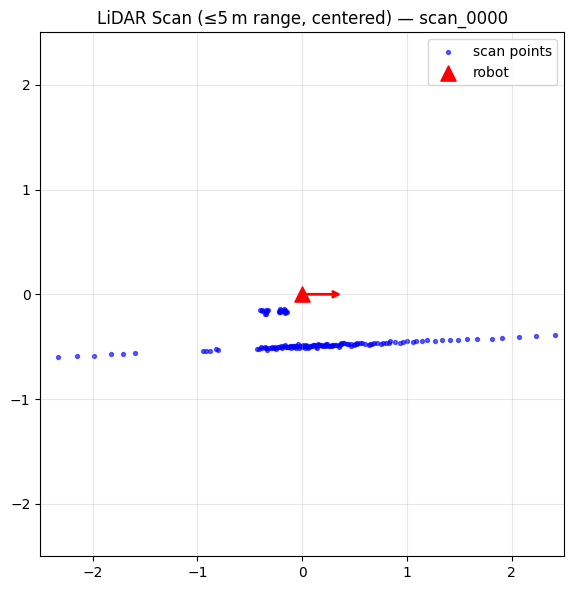

In [39]:
# ── Centered View + Heading ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Filter within 5 m
mask = r < 5.0
x_filt, y_filt = x[mask], y[mask]

# Plot scan points
ax.scatter(x_filt, y_filt, s=8, c='blue', alpha=0.6, label='scan points')

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(f"LiDAR Scan (≤5 m range, centered) — {expt_name}")
plt.tight_layout()
plt.show()


In [46]:

angles_full = angle_min + np.arange(len(ranges)) * angle_inc

arc_r, arc_a, arc_xy = extract_combined_arc(ranges, angles_full)

segments = segment_points(arc_r, arc_a, arc_xy, threshold=0.15)

print(f"Arc points after clip: {len(arc_r)}")
print(f"Angle range: {arc_a[0]:.1f}° → {arc_a[-1]:.1f}°")



segments = split_segments_by_line_deviation(
    segments,
    deviation_threshold=0.05,
    min_points=8,
    min_angle_change_deg=12.0,
    debug=True,
)

segments = [
    seg for seg in segments
    if np.median(seg[0]) < 3.0
]  

    
for k, seg in enumerate(segments):
    seg_r, seg_a, seg_xy = seg

    print(
        k,
        "n=", len(seg_xy),
        "angle=", f"{seg_a[0]:.1f}->{seg_a[-1]:.1f}",
        "start=", seg_xy[0],
        "end=", seg_xy[-1],
    )



  i=  1  a=225.5→226.5  r=0.235  cart=0.0060  tol=0.0042  rjump=0.0043  split=no
  i=  2  a=226.5→227.5  r=0.234  cart=0.0041  tol=0.0041  rjump=0.0005  split=no
  i=  3  a=227.5→228.5  r=0.243  cart=0.0099  tol=0.0041  rjump=0.0090  split=no
  i=  4  a=228.5→229.5  r=0.228  cart=0.0156  tol=0.0043  rjump=0.0151  split=no
  i=  5  a=229.5→230.5  r=0.673  cart=0.4450  tol=0.0040  rjump=0.4450  split=YES
  i=  6  a=230.5→231.5  r=0.670  cart=0.0121  tol=0.0118  rjump=0.0030  split=no
  i=  7  a=231.5→232.5  r=0.639  cart=0.0328  tol=0.0117  rjump=0.0307  split=no
  i=  8  a=232.5→233.5  r=0.642  cart=0.0116  tol=0.0112  rjump=0.0028  split=no
  i=  9  a=233.5→234.5  r=0.615  cart=0.0290  tol=0.0112  rjump=0.0269  split=no
  i= 10  a=234.5→235.5  r=0.617  cart=0.0109  tol=0.0108  rjump=0.0017  split=no
  i= 11  a=235.5→236.5  r=0.619  cart=0.0110  tol=0.0108  rjump=0.0022  split=no
  i= 12  a=236.5→237.5  r=0.633  cart=0.0177  tol=0.0108  rjump=0.0139  split=no
  i= 13  a=237.5→238.5  r=0

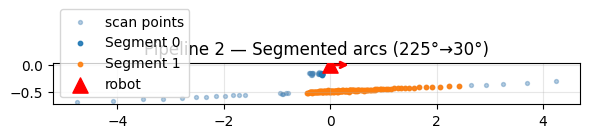

In [47]:
# ── Plot Full Scan + Segments ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segmented arc in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(f"Pipeline 2 — Segmented arcs (225°→30°)")
plt.tight_layout()
plt.show()


In [48]:
fits = smart_fit_segments(segments, min_points=8)
fits = merge_collinear(fits)

terminal_edges = detect_terminal_edges_from_fits(
    fits,
    ranges_raw=ranges,
    angles_full_rad=angles_full,
    max_range_interest=2.0,
    lookahead_beams=12,
    min_far_ratio=0.40,
    debug=True,
)



Seg 0: skipped — too few points (5)
  fit_segment: distance=0.496m  ratio=4891.3  centroid=(0.334,-0.482)
  fit_segment: ACCEPTED
Seg 1: clean  ratio=4891.3  inliers=121/121 (100%)  d=0.496m  edge=(2.413,-0.391) @ 350.8°
Wall 0: single segment  pts=121  d=0.496m  normal=[-0.043, 0.999]
  Terminal check fit 0: skipped — edge near arc boundary (350.8°)


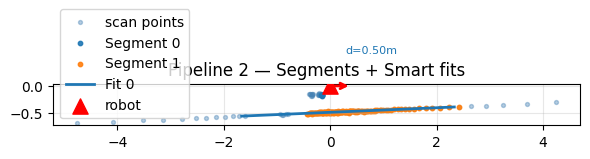

In [49]:
# ── Plot Full Scan + Segments + Smart Fits ────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segment in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Overlay fitted lines from smart_fit_segments
for j, (f, sxy) in enumerate(fits):
    n, d, c = f['normal'], f['distance'], f['centroid']

    # line direction = perpendicular to normal
    wall_dir = np.array([-n[1], n[0]])

    # extend line through centroid
    p1 = c + wall_dir * 2.0
    p2 = c - wall_dir * 2.0
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
            color=colors[j % len(colors)], lw=2, label=f'Fit {j}')

    # draw normal arrow from centroid toward robot
    ax.annotate('', xy=(c[0] + n[0], c[1] + n[1]), xytext=(c[0], c[1]),
                arrowprops=dict(arrowstyle='->', color=colors[j % len(colors)], lw=2.5))

    # label with distance
    ax.text(c[0] + n[0]*1.1, c[1] + n[1]*1.1,
            f'd={d:.2f}m', color=colors[j % len(colors)], fontsize=8)

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Pipeline 2 — Segments + Smart fits")
plt.tight_layout()
plt.show()


In [50]:
result = detect_best_corner(fits)

In [51]:
events = []

if result is not None:
    events.append({
        "type": result["type"],
        "point": result["vertex"],
        "radian_diff": result["radian_diff"],
        "angle_deg": result["angle_deg"],
        "turn_dir": "CCW" if result["radian_diff"] > 0 else "CW",
        "source": "line_intersection",
    })

for e in terminal_edges:
    events.append({
        "type": "EXTERNAL_EDGE",
        "point": e["point"],
        "radian_diff": -np.pi / 2,   # CW 90° default
        "angle_deg": 90.0,
        "turn_dir": "CW",
        "source": "terminal_dropout",
        "seg_idx": e["seg_idx"],
        "far_ratio": e["far_ratio"],
    })

def event_sort_key(ev):
    d = np.linalg.norm(ev["point"])
    return d

events.sort(key=event_sort_key)

# after distance sort, only swap INTERNAL ahead if comparable
COMPARABLE_DIST = 0.40  # meters

for i, ev in enumerate(events):
    if ev["type"] == "INTERNAL":
        internal = ev
        break
else:
    internal = None

if internal is not None:
    d_int = np.linalg.norm(internal["point"])

    closer_ext = [
        ev for ev in events
        if ev["type"] in ("EXTERNAL", "EXTERNAL_EDGE")
        and np.linalg.norm(ev["point"]) < d_int
    ]

    if closer_ext:
        d_ext = min(np.linalg.norm(ev["point"]) for ev in closer_ext)

        if abs(d_int - d_ext) < COMPARABLE_DIST:
            events.remove(internal)
            events.insert(0, internal)

for ev in events:
    p = ev["point"]
    print(
        f"{ev['type']} source={ev['source']} "
        f"turn={ev['turn_dir']} {ev['angle_deg']:.1f}° "
        f"pt=({p[0]:.3f},{p[1]:.3f})"
    )

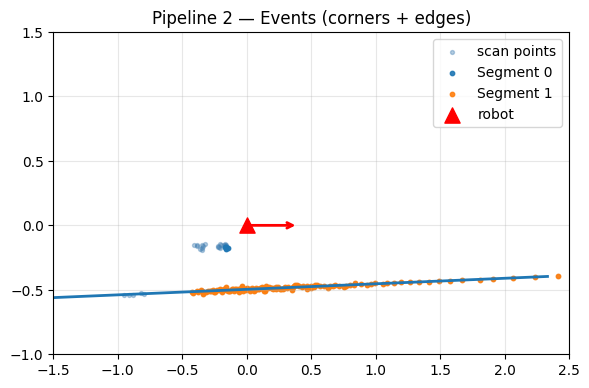

In [52]:
# ── Plot Full Scan + Segments + Events ────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Segments in different colors
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Overlay fits (optional, same as before)
for j, (f, sxy) in enumerate(fits):
    if f is None:
        continue
    n, c = f['normal'], f['centroid']
    wall_dir = np.array([-n[1], n[0]])
    p1, p2 = c + wall_dir * 2.0, c - wall_dir * 2.0
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
            color=colors[j % len(colors)], lw=2)

# Plot events
for e in events:
    px, py = e["point"]
    if e["type"] in ["INTERNAL", "EXTERNAL"]:
        ax.scatter(px, py, c='magenta', s=120, marker='o', zorder=6)
        ax.text(px, py - 0.1,
                f"{e['type']} {e['angle_deg']:.1f}°",
                color='magenta', fontsize=9, ha='center')
    elif e["type"] == "EXTERNAL_EDGE":
        ax.scatter(px, py, c='green', s=100, marker='x', zorder=6)
        ax.text(px, py - 0.1,
                f"{e['type']} seg={e['seg_idx']}",
                color='green', fontsize=9, ha='center')

# Robot marker
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_xlim(-1.5, 2.5)
ax.set_ylim(-1, 1.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Pipeline 2 — Events (corners + edges)")
plt.tight_layout()
plt.show()
